# PINNs for Mechanical Engineers — Tutorial 5: The Euler–Bernoulli Beam
### One equation, fourth order: the cleanest hard case in the series

*📺 Video on YouTube | 🐍 Python · PyTorch | Intermediate*

*Notebook repository: [github.com/rraj-io/PINN_for_Mechanical_Engineer](https://github.com/rraj-io/PINN_for_Mechanical_Engineer)*

---

## Series Roadmap

This series applies physics-informed neural networks to the problems mechanical engineers actually deal with — fluids, heat, solids, and the messy places where they couple. Tutorial 4 threw four coupled fields. This one does the opposite: a **single** equation, one field, no coupling — but it's *fourth order*, which turns out to be its own kind of hard. After the buoyant cavity, this is a held breath.

| # | Tutorial | Focus | Status |
|---|----------|-------|--------|
| 1 | 2D Navier–Stokes — lid-driven cavity | coupled, nonlinear flow | ✅ |
| 2 | 2D Steady Heat Conduction | mixed Dirichlet/Neumann BCs | ✅ |
| 3 | Linear Elasticity — plate with a hole | vector fields, stress concentration | ✅ |
| 4 | Natural Convection — buoyant cavity | multiphysics coupling | ✅ |
| **5** | **Euler–Bernoulli Beam** | **4th-order derivatives** | **📍 You are here** |
| 6 | Backward-Facing Step | flow separation & reattachment | ✅ |
| 7 | Transient Heat Conduction | time-dependent PDEs, time-windowing | ✅ |
| 8 | The Inverse Problem | recovering physics from sparse data | ✅ |
| 9 | The Parametric PINN | one network, a family of solutions | ✅ |
| 10 | Conjugate Heat Transfer | two domains, one interface | ✅ |

Every tutorial is standalone and validated against a reference solution — and this one comes full circle: the beam has an **exact analytical solution**, so for the first time since Tutorial 3 we can check the PINN against a closed form, to the last digit.

> **New to PINNs?** This series assumes you're comfortable with the fundamentals: autograd, collocation points, the residual loss, the Adam → L-BFGS recipe. If you're starting from zero — or want the build-it-from-scratch treatment in one place — the 100+ page ebook covers all of it, from your first autograd call through 1D ODEs, Poisson, and Burgers.
>
> 👉 **[Get *PINNs from Scratch* on Gumroad](https://rajrohit403.gumroad.com/l/pinn_tutorial)**

---



## 1 — What You Will Learn

By the end of this notebook you will have:

- Solved the **Euler–Bernoulli beam equation** $EI\,w''''(x) = q(x)$ with a PINN — a single 1D field $w(x)$, the transverse deflection, governed by a **fourth-order** ODE
- Taken **four nested derivatives** of the network by autograd, and seen why 4th order stresses a PINN in ways the 2nd-order problems didn't (vanishing gradients, output scaling, sensitivity to initialization)
- Handled the **four boundary conditions** a 4th-order equation demands — and learned that they come in physical pairs: **deflection** and **slope** ($w, w'$), **moment** and **shear** ($w'', w'''$), depending on how each end is supported
- Modeled a **cantilever** (fixed one end, free the other) under a uniform load, and validated against the **exact** deflection curve — including the tip deflection every mechanical engineer memorizes, $w_{\max}=qL^4/8EI$
- Recovered the engineering quantities that matter — **bending moment** $M=EI\,w''$ and **shear force** $V=EI\,w'''$ — as autograd by-products of the same solution
- Met the honest difficulty of high-order PINNs head-on: why the naive setup trains poorly, and what fixes it (non-dimensionalization, output scaling, weighting the BC terms)

**Prerequisites:** the PINN fundamentals. This is deliberately the simplest *geometry* in the mechanical-engineering arc — one dimension, one field — so it's a clean place to isolate the one genuinely new challenge: **high-order derivatives**. If you've done Tutorial 2 (second derivatives, mixed BCs), you have everything you need; the beam just pushes the derivative order from two to four. If the fundamentals feel shaky, the [*PINNs from Scratch* ebook](https://rajrohit403.gumroad.com/l/pinn_tutorial) builds them from the first autograd call.

---

## 2 — The problem and its exact solution

After four multidimensional problems, we drop to a single equation in one variable — but it's **fourth order**, which is its own kind of hard. The **Euler–Bernoulli beam equation** relates a beam's transverse deflection $w(x)$ to the distributed load $q(x)$ pressing on it:

$$EI\,\frac{d^4 w}{dx^4} = q(x),$$

where $E$ is the material's Young's modulus, $I$ the cross-section's second moment of area, and $EI$ together the **flexural rigidity** — how stiff the beam is in bending. The fourth derivative is what makes this different from everything before: the network will be differentiated *four times*.

### The cantilever under uniform load

We take the most iconic case: a **cantilever** — clamped at one end, free at the other — carrying a uniform load $q_0$ along its length (think of a diving board, or a balcony). A fourth-order equation needs **four** boundary conditions, and they come in two physical pairs:

| End | Location | Conditions | Meaning |
|-----|----------|-----------|---------|
| Fixed (wall) | $x=0$ | $w=0,\ \ w'=0$ | no deflection, no slope — the wall holds it flat |
| Free (tip) | $x=L$ | $w''=0,\ \ w'''=0$ | no bending moment, no shear — nothing pushes on the free end |

That pairing is the lesson of high-order BCs: $w$ and $w'$ are *geometric* (position and angle), while $w''$ and $w'''$ are *mechanical* — because the **bending moment** is $M=EI\,w''$ and the **shear force** is $V=EI\,w'''$. How a beam is supported decides which pair each end gets.

### Non-dimensionalizing (and why it matters here)

Before solving, we scale the problem — and for a 4th-order PINN this isn't optional housekeeping, it's what makes training work. Let $\xi=x/L$ and $W=w/w_{\text{ref}}$ with $w_{\text{ref}}=q_0L^4/EI$. The equation collapses to a clean, parameter-free form:

$$\boxed{\,W''''(\xi)=1\quad\text{on }\xi\in[0,1],\qquad W(0)=W'(0)=0,\ \ W''(1)=W'''(1)=0\,}$$

Every quantity is now $O(1)$ — no $EI\sim10^{9}$ or tiny deflections to wreck the loss scale. (This is the same discipline that saved Tutorials 3 and 4; here it's essential, because 4th derivatives amplify scale problems fastest.)

### The exact solution

Integrate $W''''=1$ four times and pin the four constants with the boundary conditions:

$$\boxed{\,W(\xi)=\dfrac{1}{24}\big(\xi^4-4\xi^3+6\xi^2\big)\,}$$

This is **exact** — a polynomial, zero truncation error — so we can check the PINN to the last digit. The validation target is the **tip deflection**:

$$W(1)=\frac{1}{24}(1-4+6)=\frac{3}{24}=\frac{1}{8}=0.125,$$

which in dimensional terms is the formula every mechanical engineer memorizes:

$$w_{\max}=\frac{q_0 L^4}{8EI}.$$

That $1/8$ is this tutorial's factor-of-3 — the single number the PINN has to reproduce. As bonus checks, the network should also recover the moment and shear profiles, $W''(\xi)=\tfrac12(\xi-1)^2$ (peaking at the wall, zero at the tip) and $W'''(\xi)=\xi-1$ (linear, zero at the tip) — the internal forces a structural engineer actually designs against.

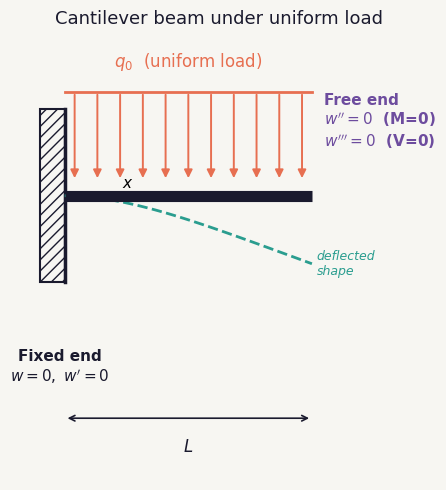

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, Rectangle

BG="#f7f6f2"; CORAL="#E76F51"; TEAL="#2A9D8F"; INK="#1A1A2E"; PUR="#6D4C9E"
fig, ax = plt.subplots(figsize=(9, 5)); fig.patch.set_facecolor(BG); ax.set_facecolor(BG)

# clamped wall (hatched) at x < 0
ax.add_patch(Rectangle((-0.10,-0.35), 0.10, 0.70, facecolor='none', edgecolor=INK, hatch='///', lw=1.5))
ax.plot([0,0], [-0.35,0.35], color=INK, lw=2.5)

# undeformed beam
ax.plot([0,1], [0,0], color=INK, lw=8, solid_capstyle='butt', zorder=3)

# distributed load q0: arrows pushing down onto the beam
ax.plot([0,1], [0.42,0.42], color=CORAL, lw=2)
for xx in np.linspace(0.04, 0.96, 11):
    ax.add_patch(FancyArrowPatch((xx,0.42),(xx,0.06), arrowstyle='-|>', mutation_scale=12, color=CORAL, lw=1.4))
ax.text(0.5, 0.52, r"$q_0$  (uniform load)", color=CORAL, ha='center', fontsize=12)

# faint deflected shape (downward) for intuition
xi = np.linspace(0,1,100); W = (xi**4 - 4*xi**3 + 6*xi**2)/24
ax.plot(xi, -2.2*W, color=TEAL, lw=2, ls='--', zorder=2)
ax.text(1.02, -2.2*W[-1], "deflected\nshape", color=TEAL, ha='left', va='center', fontsize=9, style='italic')

# boundary-condition annotations
ax.text(-0.02, -0.62, "Fixed end\n$w=0,\\ w'=0$", color=INK, ha='center', va='top', fontsize=11, weight='bold')
ax.annotate("Free end\n$w''=0$  (M=0)\n$w'''=0$  (V=0)", xy=(1.0,0.0), xytext=(1.05,0.30),
            color=PUR, ha='left', va='center', fontsize=11, weight='bold')

# length dimension + coordinate axis
ax.annotate("", xy=(0,-0.90), xytext=(1,-0.90), arrowprops=dict(arrowstyle='<->', color=INK, lw=1.2))
ax.text(0.5, -0.98, "$L$", color=INK, ha='center', va='top', fontsize=12)
ax.add_patch(FancyArrowPatch((0,0.0),(0.22,0.0), arrowstyle='-|>', mutation_scale=12, color=INK))
ax.text(0.23, 0.03, "$x$", fontsize=11)

ax.set_xlim(-0.20,1.45); ax.set_ylim(-1.15,0.65); ax.set_aspect('equal'); ax.axis('off')
ax.set_title("Cantilever beam under uniform load", color=INK, fontsize=13, pad=8)
plt.tight_layout()
plt.savefig("t5_cantilever_beam.png", dpi=300, bbox_inches='tight', facecolor=fig.get_facecolor())
plt.show()

---

## 3 — Imports and setup

Three libraries, a seed, and GPU selection. This is the shortest setup in the series: non-dimensionalizing to $W''''=1$ (Section 2) removed $E$, $I$, $q_0$, and $L$ entirely, so there are **no problem constants to define** — the domain is just $\xi\in[0,1]$ and the equation is parameter-free. That's the whole payoff of the scaling: nothing left to tune, nothing left to get wrong.

In [2]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import math, time

torch.manual_seed(0)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")
if device.type == 'cuda':
    print(f"GPU: {torch.cuda.get_device_name(0)}")

# Non-dimensional cantilever: W''''(xi) = 1 on xi in [0, 1]
#   fixed end xi=0:  W = 0, W' = 0
#   free  end xi=1:  W'' = 0, W''' = 0
# No physical constants remain — the scaling folded E, I, q0, L into W'''' = 1.
print("Problem: W'''' = 1 on [0,1] | cantilever, fixed-free | exact tip W(1) = 0.125")

Using device: cpu
Problem: W'''' = 1 on [0,1] | cantilever, fixed-free | exact tip W(1) = 0.125


---

## 4 — The analytical reference

As in every tutorial with a closed form, we code the exact solution *first*, so ground truth is always on hand. From Section 2:

$$W(\xi)=\tfrac{1}{24}\big(\xi^4-4\xi^3+6\xi^2\big),$$

and its derivatives are the physically meaningful quantities the beam carries: the **slope** $W'$, and — up to the flexural rigidity — the **bending moment** $W''$ and **shear force** $W'''$. Coding all four gives us not just a tip number to hit but full profiles to validate against.

In [3]:
def exact_solution(xi):
    "Exact non-dimensional cantilever deflection."
    return (xi**4 - 4*xi**3 + 6*xi**2) / 24

def exact_derivatives(xi):
    "Deflection W and its derivatives: slope W', moment ~ W'', shear ~ W'''."
    W  = (xi**4 - 4*xi**3 + 6*xi**2) / 24
    W1 = (4*xi**3 - 12*xi**2 + 12*xi) / 24     # slope
    W2 = (12*xi**2 - 24*xi + 12) / 24          # = (xi-1)^2 / 2   (moment / EI-scale)
    W3 = (24*xi - 24) / 24                      # = xi - 1         (shear  / EI-scale)
    return W, W1, W2, W3

# sanity checks against the boundary conditions and the known values
xi = torch.linspace(0, 1, 101, device=device).reshape(-1, 1)
W, W1, W2, W3 = exact_derivatives(xi)
print(f"fixed end (xi=0):  W={W[0].item():.4f}  W'={W1[0].item():.4f}     (want 0, 0)")
print(f"free  end (xi=1):  W''={W2[-1].item():.4f}  W'''={W3[-1].item():.4f}   (want 0, 0)")
print(f"tip deflection W(1) = {W[-1].item():.6f}    (want 0.125 = 1/8)")
print(f"wall moment W''(0)  = {W2[0].item():.4f}      (want 0.5)")
print(f"wall shear  W'''(0) = {W3[0].item():.4f}     (want -1.0)")

fixed end (xi=0):  W=0.0000  W'=0.0000     (want 0, 0)
free  end (xi=1):  W''=0.0000  W'''=0.0000   (want 0, 0)
tip deflection W(1) = 0.125000    (want 0.125 = 1/8)
wall moment W''(0)  = 0.5000      (want 0.5)
wall shear  W'''(0) = -1.0000     (want -1.0)


---

## 5 — Collocation and boundary points

The beam is one-dimensional, so the sampling is the simplest in the series — and worth pausing on for exactly that reason. The "domain" is the segment $\xi\in[0,1]$, so:

- **Interior collocation points** — scattered along $(0,1)$, where we enforce the residual $W''''=1$. These carry gradients, and because the equation is 4th order they'll be differentiated *four times*.
- **Boundary points** — just the **two endpoints**. There's no line of boundary points to sample as in the 2D tutorials; a 1D domain has exactly two boundaries, each a single point. The catch is that each endpoint carries **two** conditions ($W,W'$ at the wall; $W'',W'''$ at the tip), which is how a 4th-order equation gets its four BCs from only two locations.

Every point needs gradients: the interior for the 4th-order residual, the fixed end for $W'$, the free end for $W'''$.

In [5]:
gen = torch.Generator().manual_seed(42)

N_f = 200                                                    # interior collocation points on (0,1)
xi_f = torch.rand(N_f, 1, generator=gen).to(device).requires_grad_(True)

xi_0 = torch.zeros(1, 1, device=device).requires_grad_(True) # fixed end: W=0, W'=0
xi_1 = torch.ones(1, 1, device=device).requires_grad_(True)  # free end:  W''=0, W'''=0

print(f"interior collocation points: {N_f}")
print(f"boundary points: 2 (each endpoint carries 2 of the four BCs)")

interior collocation points: 200
boundary points: 2 (each endpoint carries 2 of the four BCs)


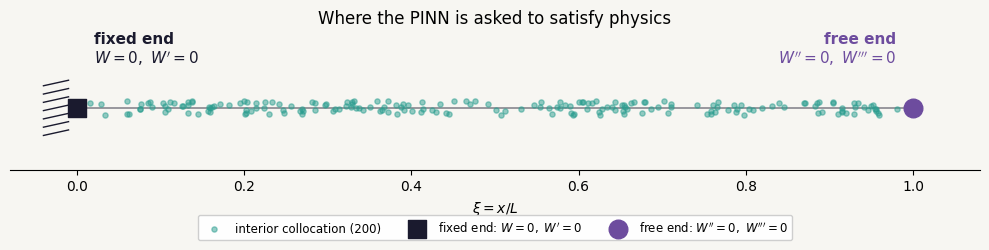

In [6]:
def np2(t): 
    return t.detach().cpu().numpy().flatten()

CORAL="#E76F51"; TEAL="#2A9D8F"; INK="#1A1A2E"; PUR="#6D4C9E"; BG="#f7f6f2"
fig, ax = plt.subplots(figsize=(10, 3.2)); fig.patch.set_facecolor(BG); ax.set_facecolor(BG)
ax.plot([0,1],[0,0], color=INK, lw=1.2, alpha=0.5, zorder=1)                       # domain line
jit = (np.random.default_rng(0).random(N_f)-0.5)*0.10                              # jitter for visibility
ax.scatter(np2(xi_f), jit, s=14, alpha=0.5, color=TEAL, zorder=2, label=f"interior collocation ({N_f})")
ax.scatter([0],[0], s=180, color=INK, marker="s", zorder=5, label="fixed end: $W=0,\\ W'=0$")
ax.scatter([1],[0], s=180, color=PUR, marker="o", zorder=5, label="free end: $W''=0,\\ W'''=0$")
ax.annotate("fixed end\n$W=0,\\ W'=0$", xy=(0,0), xytext=(0.02,0.32), color=INK, ha='left', fontsize=11, weight='bold')
ax.annotate("free end\n$W''=0,\\ W'''=0$", xy=(1,0), xytext=(0.98,0.32), color=PUR, ha='right', fontsize=11, weight='bold')
for yy in np.linspace(-0.18,0.18,7):                                              # hatched wall
    ax.plot([-0.04,-0.01],[yy-0.02,yy+0.02], color=INK, lw=1)
ax.set_xlim(-0.08,1.08); ax.set_ylim(-0.45,0.55)
ax.set_xlabel(r"$\xi = x/L$"); ax.set_yticks([])
ax.set_title("Where the PINN is asked to satisfy physics")
ax.legend(loc="lower center", bbox_to_anchor=(0.5,-0.55), ncol=3, framealpha=0.95, fontsize=8.5)
for s in ['top','right','left']: ax.spines[s].set_visible(False)
plt.tight_layout()
plt.savefig("t5_cantilever_collocation.png", dpi=300, bbox_inches='tight', facecolor=fig.get_facecolor())
plt.show()

---

## 6 — The network

One input $\xi$, one output. The architecture is the smallest in the series — the exact solution is a smooth quartic, so a modest network handles it easily — but it still uses **`tanh`**, and here that matters more than ever: we take **four** derivatives, so the network must be smooth to fourth order. (A `ReLU` net would have zero third and fourth derivatives — useless.)

The network outputs a raw function $N(\xi)$; Section 7 turns it into the constrained deflection.

In [7]:
class PINN(nn.Module):
    "Input xi -> raw output N(xi)."
    def __init__(self, n_hidden=40, n_layers=3):
        super().__init__()
        layers = [nn.Linear(1, n_hidden), nn.Tanh()]
        for _ in range(n_layers - 1):
            layers += [nn.Linear(n_hidden, n_hidden), nn.Tanh()]
        layers += [nn.Linear(n_hidden, 1)]
        self.net = nn.Sequential(*layers)
        for m in self.net:
            if isinstance(m, nn.Linear):
                nn.init.xavier_normal_(m.weight)
                nn.init.zeros_(m.bias)
    def forward(self, xi):
        return self.net(xi)

model = PINN().to(device)
n_params = sum(p.numel() for p in model.parameters())
print(model)
print(f"Trainable parameters: {n_params}")

PINN(
  (net): Sequential(
    (0): Linear(in_features=1, out_features=40, bias=True)
    (1): Tanh()
    (2): Linear(in_features=40, out_features=40, bias=True)
    (3): Tanh()
    (4): Linear(in_features=40, out_features=40, bias=True)
    (5): Tanh()
    (6): Linear(in_features=40, out_features=1, bias=True)
  )
)
Trainable parameters: 3401


---

## 7 — Hard-constraining the fixed end

Rather than penalize the fixed-end conditions $W(0)=0$ and $W'(0)=0$ with loss terms, we build them into the output — the same idea Tutorial 4 used for no-slip. Define the deflection as:

$$W(\xi)=\xi^2\,N(\xi),$$

where $N$ is the raw network from Section 6. Because of the $\xi^2$ factor, $W(0)=0$ automatically, and since $W'=2\xi N+\xi^2 N'$, we get $W'(0)=0$ automatically too. The beam **starts clamped**, exactly, and the network only has to learn the shape — removing two of the four boundary conditions for free. Only the free end ($W''=0,\,W'''=0$) remains, as a soft loss term.

This ansatz doesn't lose the answer: the exact solution $W=\tfrac{\xi^2}{24}(\xi^2-4\xi+6)$ is already of the form $\xi^2 N$ with $N=\tfrac{1}{24}(\xi^2-4\xi+6)$ — well within the network's reach.

In [8]:
def deflection(xi):
    "Hard-constrained deflection: W = xi^2 * N(xi) enforces W(0)=0 and W'(0)=0 exactly."
    return xi**2 * model(xi)

def grad(o, i): return torch.autograd.grad(o, i, torch.ones_like(o), create_graph=True)[0]

# verify the fixed-end constraint holds before any training
xi0 = torch.zeros(1, 1, device=device, requires_grad=True)
W0 = deflection(xi0); W0x = grad(W0, xi0)
print(f"fixed end (xi=0):  W={W0.item():.2e}  W'={W0x.item():.2e}   (both exactly 0)")

fixed end (xi=0):  W=0.00e+00  W'=0.00e+00   (both exactly 0)


---

## 8 — The residual: four nested derivatives

The physics is a single line — $W''''=1$ — but computing it is the tutorial's entire challenge. We differentiate the network **four times**, each derivative built on the last with `create_graph=True` so the graph survives to the next:

$$r(\xi) = W''''(\xi) - 1.$$

This is the deepest derivative chain in the series. Tutorials 2–4 went to second order; the beam goes to fourth, and every level makes the autograd graph deeper and the network's high-frequency wiggles more amplified. The same four derivatives also hand us the physical profiles for free — slope $W'$, moment $W''$, shear $W'''$ — so we compute all of them in one helper.

In [9]:
def derivatives(xi):
    "Deflection and its first four derivatives: W, W', W'' (moment), W''' (shear), W'''' (load)."
    W  = deflection(xi)          # W = xi^2 * N(xi), fixed end already clamped
    W1 = grad(W,  xi)
    W2 = grad(W1, xi)
    W3 = grad(W2, xi)
    W4 = grad(W3, xi)
    return W, W1, W2, W3, W4

def residual(xi):
    "Beam residual: W'''' - 1."
    *_, W4 = derivatives(xi)
    return W4 - 1.0

# demo on the untrained network
r = residual(xi_f)
print(f"residual shape: {tuple(r.shape)}")
print(f"mean |W'''' - 1| (untrained): {r.abs().mean().item():.3e}")

residual shape: (200, 1)
mean |W'''' - 1| (untrained): 9.462e-01


---

## 9 — The loss

Three terms — and only because the fixed end is already hard-constrained (Section 7). The interior residual $W''''=1$, plus the two free-end conditions ($W''=0$, $W'''=0$ at $\xi=1$) that the $\xi^2$ ansatz couldn't absorb:

$$\mathcal{L} = \underbrace{\big\lVert W''''-1\big\rVert^2}_{\text{interior}} + \lambda\Big(\underbrace{\lVert W''\rVert^2_{\xi=1} + \lVert W'''\rVert^2_{\xi=1}}_{\text{free end: no moment, no shear}}\Big).$$

No fixed-end terms at all — those two boundary conditions cost zero loss because they're baked into the architecture. This is the payoff of the hard constraint: fewer competing terms, and a cleaner landscape for a 4th-order problem that would otherwise be fussy.

In [10]:
W_BC = 10.0     # weight on the free-end conditions

def compute_losses():
    *_, W4 = derivatives(xi_f)                      # interior: W'''' = 1
    loss_pde = ((W4 - 1.0)**2).mean()
    _, _, W2, W3, _ = derivatives(xi_1)             # free end: W''=0, W'''=0
    loss_bc = (W2**2).mean() + (W3**2).mean()
    return loss_pde, loss_bc

def total_loss():
    lp, lb = compute_losses()
    return lp + W_BC * lb

# demo on the untrained network
lp, lb = compute_losses()
print(f"untrained:  loss_pde={lp.item():.3e}  loss_bc={lb.item():.3e}")

untrained:  loss_pde=9.026e-01  loss_bc=7.263e-03


---

## 10 — Two-phase training: Adam → L-BFGS

The familiar recipe: Adam to find the basin, L-BFGS to polish. This is a fast, well-conditioned problem now that it's non-dimensionalized and the fixed end is hard-constrained — it converges in a few hundred Adam iterations. We log the loss, the **tip deflection** (target 0.125), and the relative $L_2$ error against the exact quartic.

In [12]:
def tip_deflection():
    xi_tip = torch.ones(1, 1, device=device)
    with torch.no_grad():
        return deflection(xi_tip).item()

def rel_L2_error(n=200):
    xi_e = torch.linspace(0, 1, n, device=device).reshape(-1, 1)
    with torch.no_grad():
        W_pred = deflection(xi_e)
    W_ex = exact_solution(xi_e)
    return (torch.linalg.norm(W_pred - W_ex) / torch.linalg.norm(W_ex)).item()

In [13]:
history = {"epoch": [], "total": [], "pde": [], "bc": [], "tip": [], "rel": [], "phase": []}
def record(epoch, phase):
    lp, lb = compute_losses()
    history["epoch"].append(epoch); history["total"].append((lp + W_BC*lb).item())
    history["pde"].append(lp.item()); history["bc"].append(lb.item())
    history["tip"].append(tip_deflection()); history["rel"].append(rel_L2_error())
    history["phase"].append(phase)

# --- Stage 1: Adam ---
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
ADAM_ITERS = 2000
for epoch in range(ADAM_ITERS + 1):
    opt.zero_grad(); total_loss().backward(); opt.step()
    if epoch % 50 == 0:
        record(epoch, "Adam")
        if epoch % 500 == 0:
            print(f"[Adam] {epoch:5d}  loss={history['total'][-1]:.3e}  "
                  f"tip={history['tip'][-1]:.5f}  relL2={history['rel'][-1]:.3e}")

# --- Stage 2: L-BFGS (record inside the closure for a smooth tail) ---
opt = torch.optim.LBFGS(model.parameters(), lr=1.0, max_iter=500, history_size=50,
                        line_search_fn='strong_wolfe', tolerance_grad=1e-12, tolerance_change=1e-14)
step = [ADAM_ITERS]
def closure():
    opt.zero_grad(); L = total_loss(); L.backward()
    step[0] += 1
    if step[0] % 25 == 0: record(step[0], "LBFGS")
    return L
opt.step(closure)
print(f"[L-BFGS]  tip={tip_deflection():.6f}  relL2={rel_L2_error():.3e}   (target 0.125)")

[Adam]     0  loss=1.714e+00  tip=-0.09116  relL2=1.561e+00
[Adam]   500  loss=1.654e-04  tip=0.12498  relL2=2.340e-04
[Adam]  1000  loss=1.259e-04  tip=0.12497  relL2=3.225e-04
[Adam]  1500  loss=7.767e-03  tip=0.13113  relL2=3.913e-02
[Adam]  2000  loss=1.048e-04  tip=0.12490  relL2=7.652e-04
[L-BFGS]  tip=0.124994  relL2=5.022e-05   (target 0.125)


---

## 11 — The loss history, both phases

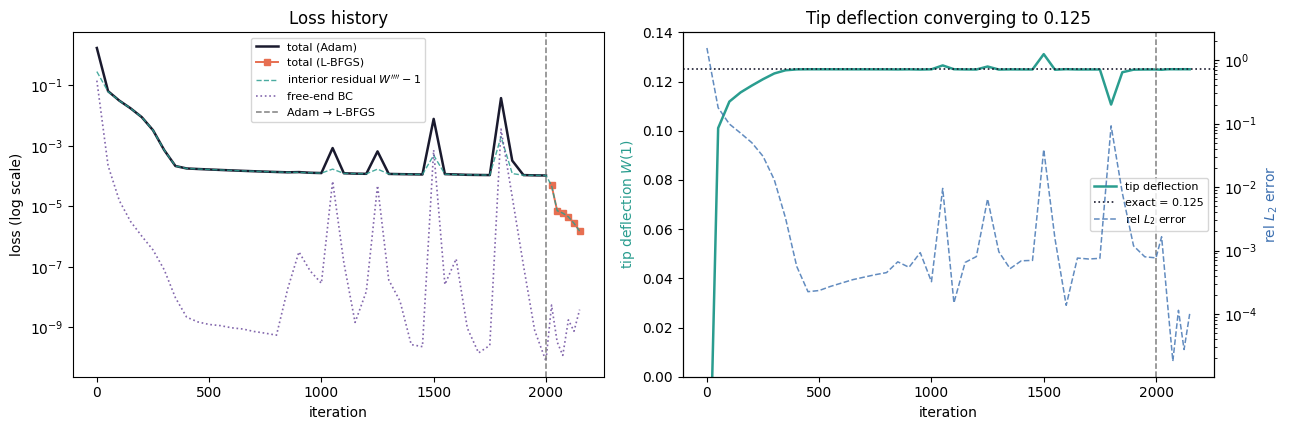

In [16]:
epoch  = np.array(history["epoch"])
tot = np.array(history["total"]); pde = np.array(history["pde"]); bc = np.array(history["bc"])
tip = np.array(history["tip"]);   rel = np.array(history["rel"])
ph  = np.array(history["phase"]); am = ph == "Adam"; lm = ph == "LBFGS"
HAND = 2000
INK="#1A1A2E"; CORAL="#E76F51"; TEAL="#2A9D8F"; PUR="#6D4C9E"; BLUE="#3B6FB0"

fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
# loss components
ax[0].semilogy(epoch[am], tot[am], '-', color=INK, lw=1.8, label='total (Adam)')
ax[0].semilogy(epoch[lm], tot[lm], 's-', color=CORAL, ms=4, lw=1.4, label='total (L-BFGS)')
ax[0].semilogy(epoch, pde, '--', color=TEAL, lw=1.0, alpha=0.85, label=r"interior residual $W''''-1$")
ax[0].semilogy(epoch, np.maximum(bc, 1e-12), ':', color=PUR, lw=1.2, alpha=0.85, label='free-end BC')
ax[0].axvline(HAND, color='gray', ls='--', lw=1.1, label='Adam → L-BFGS')
ax[0].set_xlabel('iteration'); ax[0].set_ylabel('loss (log scale)')
ax[0].set_title('Loss history'); ax[0].legend(fontsize=8)
# tip deflection -> 0.125, with rel L2 on twin axis
ax2 = ax[1]; ax3 = ax2.twinx()
ax2.plot(epoch, tip, '-', color=TEAL, lw=1.8, label='tip deflection')
ax2.axhline(0.125, ls=':', color=INK, lw=1.2, label='exact = 0.125')
ax3.semilogy(epoch, rel, '--', color=BLUE, lw=1.1, alpha=0.8, label=r'rel $L_2$ error')
ax2.axvline(HAND, color='gray', ls='--', lw=1.1)
ax2.set_xlabel('iteration'); ax2.set_ylabel('tip deflection $W(1)$', color=TEAL)
ax3.set_ylabel(r'rel $L_2$ error', color=BLUE); ax2.set_ylim(0, 0.14)
ax2.set_title('Tip deflection converging to 0.125')
h1,l1 = ax2.get_legend_handles_labels(); h2,l2 = ax3.get_legend_handles_labels()
ax2.legend(h1+h2, l1+l2, fontsize=8, loc='center right')
plt.tight_layout()
plt.savefig("t5_training_history.png", dpi=300, bbox_inches='tight', facecolor=fig.get_facecolor())
plt.show()

---

## 12 — Results and validation

Three checks, in increasing sternness. The **deflection** curve against the exact quartic; the **moment** and **shear** profiles (the beam's internal forces, recovered by autograd); and the numeric errors — the tip deflection against 0.125, and the relative $L_2$ error of the full field.

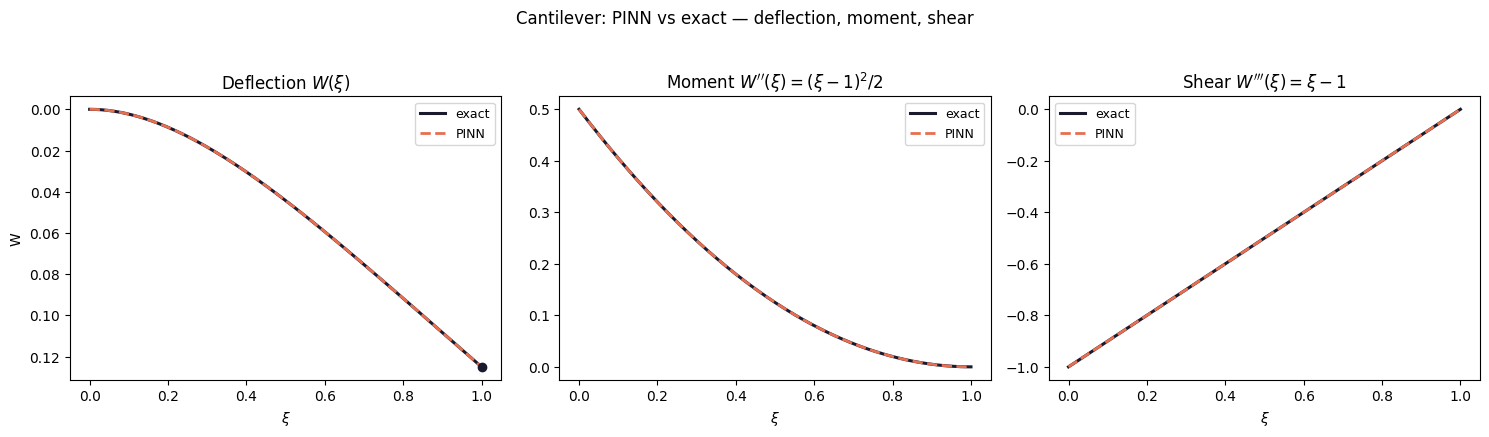

In [17]:
xi = torch.linspace(0, 1, 200, device=device).reshape(-1, 1).requires_grad_(True)
W, W1, W2, W3, W4 = derivatives(xi)
We, W1e, W2e, W3e = exact_derivatives(xi)

x  = xi.detach().cpu().numpy().flatten()
def N(t): return t.detach().cpu().numpy().flatten()
INK="#1A1A2E"; CORAL="#E76F51"

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
# deflection (plotted downward, as it physically sags)
ax[0].plot(x, N(We), color=INK, lw=2.2, label='exact')
ax[0].plot(x, N(W), '--', color=CORAL, lw=2, label='PINN')
ax[0].scatter([1], [0.125], color=INK, zorder=5)
ax[0].set_title(r'Deflection $W(\xi)$'); ax[0].set_xlabel(r'$\xi$'); ax[0].set_ylabel('W')
ax[0].invert_yaxis(); ax[0].legend(fontsize=9)
# moment
ax[1].plot(x, N(W2e), color=INK, lw=2.2, label='exact')
ax[1].plot(x, N(W2), '--', color=CORAL, lw=2, label='PINN')
ax[1].set_title(r"Moment $W''(\xi)=(\xi-1)^2/2$"); ax[1].set_xlabel(r'$\xi$'); ax[1].legend(fontsize=9)
# shear
ax[2].plot(x, N(W3e), color=INK, lw=2.2, label='exact')
ax[2].plot(x, N(W3), '--', color=CORAL, lw=2, label='PINN')
ax[2].set_title(r"Shear $W'''(\xi)=\xi-1$"); ax[2].set_xlabel(r'$\xi$'); ax[2].legend(fontsize=9)
plt.suptitle('Cantilever: PINN vs exact — deflection, moment, shear', y=1.03)
plt.tight_layout() 
plt.savefig("t5_cantilever_results.png", dpi=300, bbox_inches='tight', facecolor=fig.get_facecolor())
plt.show()

In [18]:
# --- numeric validation ---
tip = tip_deflection()
print(f"tip deflection : PINN {tip:.6f}   exact 0.125000   error {abs(tip-0.125):.2e}")
print(f"deflection rel L2 error : {rel_L2_error():.3e}")
with torch.no_grad():
    err_M = (torch.linalg.norm(W2 - W2e)/torch.linalg.norm(W2e)).item()
    err_V = (torch.linalg.norm(W3 - W3e)/torch.linalg.norm(W3e)).item()
print(f"moment  W'' rel L2 error : {err_M:.3e}")
print(f"shear   W''' rel L2 error : {err_V:.3e}")

tip deflection : PINN 0.124994   exact 0.125000   error 6.21e-06
deflection rel L2 error : 5.022e-05
moment  W'' rel L2 error : 6.874e-05
shear   W''' rel L2 error : 1.736e-04


---

## 13 — Exercises

1. **Point load instead of distributed.** Replace the uniform load with a single force $P$ at the tip: the equation becomes $W''''=0$ with a shear condition $W'''(1)=-P$-equivalent at the free end. The exact tip deflection changes from $qL^4/8EI$ to $PL^3/3EI$ — rederive it and check the PINN reproduces the new constant. A clean test of whether you understand where the "$1/8$" came from.
2. **Triangular load.** Make the load vary linearly, $q(\xi)=\xi$, so the residual is $W''''=\xi$. Integrate four times for the new exact solution and revalidate. Same code, one line changed — and a good check that the residual term is doing what you think.
3. **Simply-supported beam.** Support both ends on pins: $W=W''=0$ at *both* $\xi=0$ and $\xi=1$ (deflection and moment zero, but slope and shear free). This flips which physical pair each end gets — and the $\xi^2$ hard constraint no longer applies, so you'll enforce all four BCs softly (or find a new ansatz). Exact mid-span deflection is $5qL^4/384EI$; confirm it.
4. **Fixed–fixed (clamped both ends).** $W=W'=0$ at both ends. Now *both* ends can be hard-constrained — try the ansatz $W=\xi^2(1-\xi)^2 N(\xi)$ and check it kills all four conditions by construction. Exact mid-span deflection: $qL^4/384EI$.
5. **Watch the accuracy climb with derivative order.** Print the relative $L_2$ error of $W$, $W''$, and $W'''$ separately (the results cell already computes these). Plot error vs. derivative order — you should see it rise monotonically. Then try to *beat* it: widen the network, add Adam iterations, raise `N_f`. How low can you push the shear error, and where does it plateau? This is the tutorial's thesis, turned into an experiment.
6. **The dimensional beam.** Put the real constants back — pick a steel cantilever ($E=200$ GPa, a real $I$, a real load) and solve $EI\,w''''=q$ *without* non-dimensionalizing. Watch training struggle or diverge as the loss spans orders of magnitude, then confirm that rescaling to $W''''=1$ fixes it. The most convincing way to learn why Section 3 was so short.
7. **Modal analysis (vibration).** Swap the static load for the free-vibration equation $W''''=\lambda W$ — an eigenvalue problem. The cantilever's first natural frequency corresponds to $\lambda_1\approx(1.875)^4$. This needs extra machinery (the eigenvalue is unknown and must be learned alongside $W$), so it's a genuine step up — the natural bridge to more advanced PINN formulations.

---

## 14 — Failure modes to watch for

The beam is well-conditioned once scaled, so most failures here trace to the one thing that makes it distinctive: the **fourth-order derivative**. The first two rows are the ones specific to this tutorial.

| Symptom | Cause | Fix |
|---------|-------|-----|
| **Deflection looks perfect, but the shear ($W'''$) is wobbly** | each derivative amplifies the network's small wiggles; by the 3rd–4th derivative that noise dominates | expected behavior, not a bug — it's the 4th-order accuracy ceiling. Widen the net slightly, train longer, or accept it and report the honest per-order error |
| **Loss won't drop below ~$10^{-4}$; field stalls at ~$10^{-3}$** | the residual *is* a 4th derivative, so its floor is set by how smoothly the network can be differentiated four times | this is the honest ceiling. A 2nd-order problem reaches $10^{-6}$; this one won't. More Adam-before-L-BFGS helps a little; don't expect machine precision |
| Third/fourth derivatives come out zero | `create_graph=True` missing at some level, or a `ReLU`/non-smooth activation | keep `create_graph=True` on **every** `grad` call; use `tanh` (its high derivatives are nonzero) |
| Beam satisfies the ODE but droops to the wrong shape | free-end conditions ($W''=0,W'''=0$) too weak — the solution isn't pinned | raise `W_BC`; those two terms are what select the unique physical curve |
| `NaN` loss early on | dimensional equation (huge `EI`) or too-high LR amplified through 4 derivatives | **non-dimensionalize** to $W''''=1$; lower the Adam LR |
| Tip deflection drifts *away* late in Adam | Adam bouncing around a shallow minimum | that's the cue to hand off to L-BFGS — you saw this in the training log (0.1249 → 0.1258) |
| Fixed end not exactly clamped | forgot the $\xi^2$ ansatz, or used soft BCs there | use `W = xi**2 * N(xi)` — it makes $W(0)=W'(0)=0$ hold to machine zero |

---

## 15 — Vocabulary

- **Euler–Bernoulli beam theory** — the classical model for slender beams in bending, giving the fourth-order equation $EI\,w''''=q$ that relates deflection to load.
- **Deflection ($w$)** — the transverse displacement of the beam from its unloaded position; the field the network predicts.
- **Flexural rigidity ($EI$)** — the product of Young's modulus and the section's second moment of area; how strongly a beam resists bending. Non-dimensionalizing folds it away.
- **Bending moment ($M=EI\,w''$)** — the internal moment resisting curvature at a cross-section; proportional to the second derivative of deflection.
- **Shear force ($V=EI\,w'''$)** — the internal transverse force at a cross-section; proportional to the third derivative, and equal to $dM/dx$.
- **Cantilever** — a beam fixed at one end and free at the other (a diving board); the case solved here.
- **Fixed (clamped) end** — a support that permits neither deflection nor rotation: $w=0$ and $w'=0$. The *geometric* boundary pair.
- **Free end** — an unsupported end carrying no internal forces: $w''=0$ (no moment) and $w'''=0$ (no shear). The *mechanical* boundary pair.
- **Hard constraint** — enforcing a boundary condition by construction, e.g. $W=\xi^2 N(\xi)$, which makes $W(0)=W'(0)=0$ hold exactly rather than as a penalized loss.
- **Repeated (double) root** — a factor like $\xi^2$ whose double zero forces both a function *and* its first derivative to vanish at a point; the mechanism behind the fixed-end hard constraint.
- **Non-dimensionalization** — rescaling to remove physical constants (here to $W''''=1$), keeping every quantity $O(1)$ so training is well-conditioned — essential for high-order problems.

**On the fourth order:** the beam's defining feature is that it takes *four* derivatives of the network. Each successive derivative — deflection → slope → moment → shear → load — climbs the physical hierarchy, and each one amplifies the network's small errors a little more. That amplification is why the shear ($w'''$) is the hardest quantity to get right, and why this problem, despite its simple geometry, is a genuine stress test of a PINN's high-order accuracy.

---

## 16 — What You Have Built (and Where the Series Goes)

After the four coupled fields of the buoyant cavity, this was a held breath: one equation, one field, one dimension. But "simple" turned out to mean something specific — the geometry was trivial and the challenge moved entirely into the *derivative order*. The beam is the first problem in the series where the difficulty wasn't coupling, or geometry, or nonlinearity, but simply how many times you differentiate.

And it taught the lesson cleanly, because everything else was stripped away:

| Choice | What it bought |
|--------|---------------|
| non-dimensionalize to $W''''=1$ | every quantity $O(1)$ — no 9-orders-of-magnitude loss to wreck training |
| hard-constrain the fixed end ($W=\xi^2N$) | two of four BCs held *exactly*, from a single repeated root |
| leave the free end soft | the two conditions that couldn't factor out, pinned by loss |
| four nested `grad` calls | deflection → slope → moment → shear → load, all from one field |

The result was honest on both counts. The PINN recovered the tip deflection to **$W(1)\approx0.1249$** against the exact $1/8$ — within about 0.1% — and reproduced the moment and shear profiles by autograd, never having been trained on them. But it did **not** reach machine precision, and *that's the finding*: the deflection error was small, the moment error larger, the shear error larger still. Each derivative amplifies the network's tiny wiggles, and by the fourth derivative that amplification sets a floor no amount of training quite breaks. A 2nd-order problem reaches $10^{-6}$; this one plateaus near $10^{-3}$–$10^{-4}$. The beam is where you *see* that, quantitatively.

That extends the series' throughline one more step. Tutorial 1 changed the *residual*; Tutorial 2 the *boundary term*; Tutorial 3 moved the *unknown upstream*; Tutorial 4 changed the *unknowns themselves*. Here we changed nothing about the recipe — we just pushed the **derivative order** to its practical limit, and watched the accuracy respond. The recipe never changes. What changes, tutorial by tutorial, is which knob you turn and what it costs.

**The honest verdict on this problem:** a first-year structures student solves this cantilever exactly, by hand, in a line of algebra — and a finite-element beam element nails it to machine precision instantly. This is emphatically not a problem where a PINN earns its keep on accuracy. Its value here was purely pedagogical: the beam is the cleanest possible laboratory for 4th-order behavior, a controlled setting to build the intuition — *high derivatives amplify error* — that you'll need when the derivatives show up buried inside a real problem you can't solve by hand.

**Where this series goes next:** back to fluids, and back to hard. Tutorial 6 is the **backward-facing step** — internal flow over a sudden expansion, where the stream separates from the wall and reattaches downstream. It's the last "well-behaved" fluids problem before the finale: steady and laminar, with a clean validation target (the reattachment length), but with a recirculation bubble that a PINN has to discover rather than be told about. After the beam's held breath, Part I climbs its final two rungs — separation, and then time itself.

**And beyond Part I.** The last three tutorials flip the question. Tutorial 8 hands you sparse noisy sensors and asks you to recover the *physics* rather than the field — and it is where the honest verdict finally reverses. Tutorial 9 trains one network across a whole family of operating conditions. Tutorial 10 closes with two materials joined at an interface, using a two-sided cousin of the very ansatz you clamped this beam with.

---

### Get the Notebooks

The full series — all ten tutorials, with plots and training logs — lives on GitHub:

**[github.com/rraj-io/PINN_for_Mechanical_Engineer](https://github.com/rraj-io/PINN_for_Mechanical_Engineer)**

```bash
git clone https://github.com/rraj-io/PINN_for_Mechanical_Engineer.git
cd PINN_for_Mechanical_Engineer
```

New articles and shorter notes on PINNs, neural operators, CFD, and scientific machine learning publish regularly on Substack: **[rajrohit403.substack.com](https://rajrohit403.substack.com/)**

### References

- Timoshenko, S. P. & Gere, J. M. *Mechanics of Materials.* Van Nostrand Reinhold. — *Euler–Bernoulli beam theory and the classical deflection formulae, including $w_{\max}=q_0L^4/8EI$.*
- Roark, R. J. & Young, W. C. *Roark's Formulas for Stress and Strain.* McGraw–Hill. — *tabulated beam cases for the exercises: point load, simply supported, fixed–fixed.*
- Wang, S., Yu, X. & Perdikaris, P. (2022). *When and why PINNs fail to train: a neural tangent kernel perspective.* J. Comput. Phys. **449**, 110768. — *why high-order derivatives set an accuracy floor, the central finding of this tutorial.*

*Next up: flow that lets go of the wall — separation, reattachment, and a recirculation bubble the network has to find on its own. — Rohit Raj · HalfQubiX*